# 02 · Exploratory Data Analysis

Explores trends and relationships across CPI, unemployment, the Fed Funds rate,
and the S&P 500. Uses **both** processed datasets from notebook 01 so that
trend analysis isn't artificially cut short by SP500's limited history.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set(style="whitegrid")
PROC = "../Data/processed/"
VIS = "../visuals/"
os.makedirs(VIS, exist_ok=True)

macro = pd.read_csv(PROC + "macro_long_history.csv", parse_dates=["observation_date"])
full = pd.read_csv(PROC + "master_monthly_dataset.csv", parse_dates=["observation_date"])

print("macro (long history):", macro.shape)
print("full (with SP500):", full.shape)
macro.describe()

macro (long history): (857, 4)
full (with SP500): (58, 5)


,observation_date,CPIAUCSL,UNRATE,FEDFUNDS
count,857,857.000000,857.000000,857.000000
mean,1990-03-02 02:58:06.581096,134.235880,5.804084,4.604399
min,1954-07-01 00:00:00,26.710000,3.400000,0.050000
25%,1972-05-01 00:00:00,41.600000,4.500000,1.910000
50%,1990-03-01 00:00:00,128.600000,5.600000,4.330000
75%,2008-01-01 00:00:00,211.445000,6.900000,6.130000
max,2025-12-01 00:00:00,326.030000,14.800000,19.100000
std,NaN,87.516095,1.669355,3.544938


## Long-run trends (1954-2025)

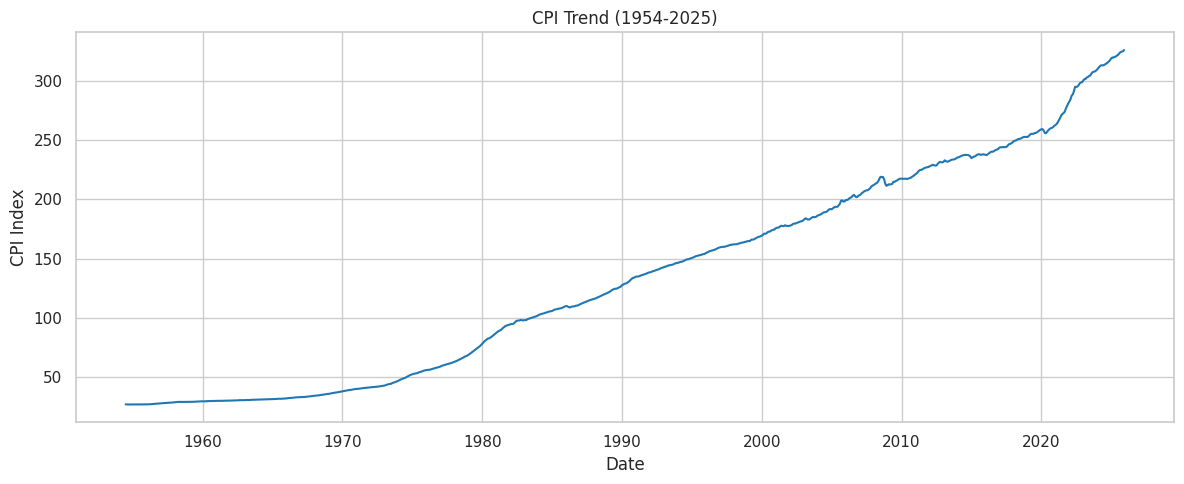

In [2]:
def lineplot(df, col, title, ylabel, color, fname):
    plt.figure(figsize=(12, 5))
    sns.lineplot(data=df, x="observation_date", y=col, color=color)
    plt.title(title); plt.xlabel("Date"); plt.ylabel(ylabel)
    plt.tight_layout()
    plt.savefig(VIS + fname, dpi=150)
    plt.show()

lineplot(macro, "CPIAUCSL", "CPI Trend (1954-2025)", "CPI Index", "tab:blue", "cpi_trend_long_history.png")

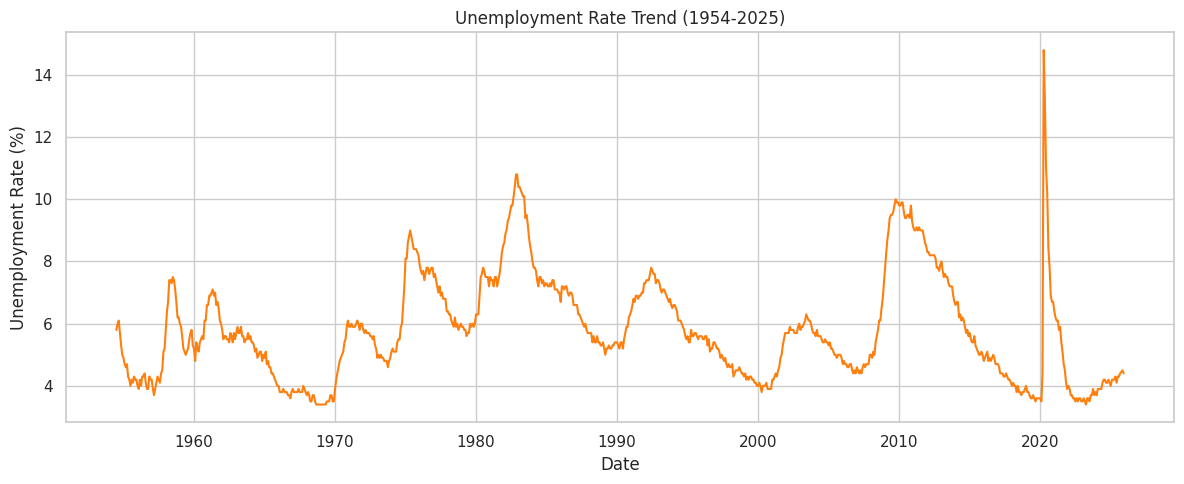

In [3]:
lineplot(macro, "UNRATE", "Unemployment Rate Trend (1954-2025)", "Unemployment Rate (%)", "tab:orange", "unrate_trend_long_history.png")

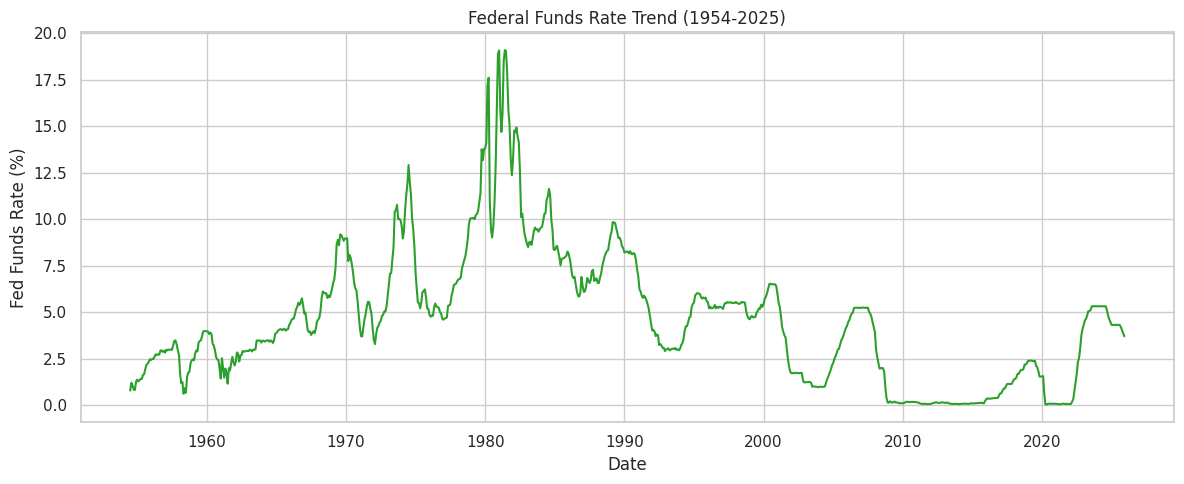

In [4]:
lineplot(macro, "FEDFUNDS", "Federal Funds Rate Trend (1954-2025)", "Fed Funds Rate (%)", "tab:green", "fedfunds_trend_long_history.png")

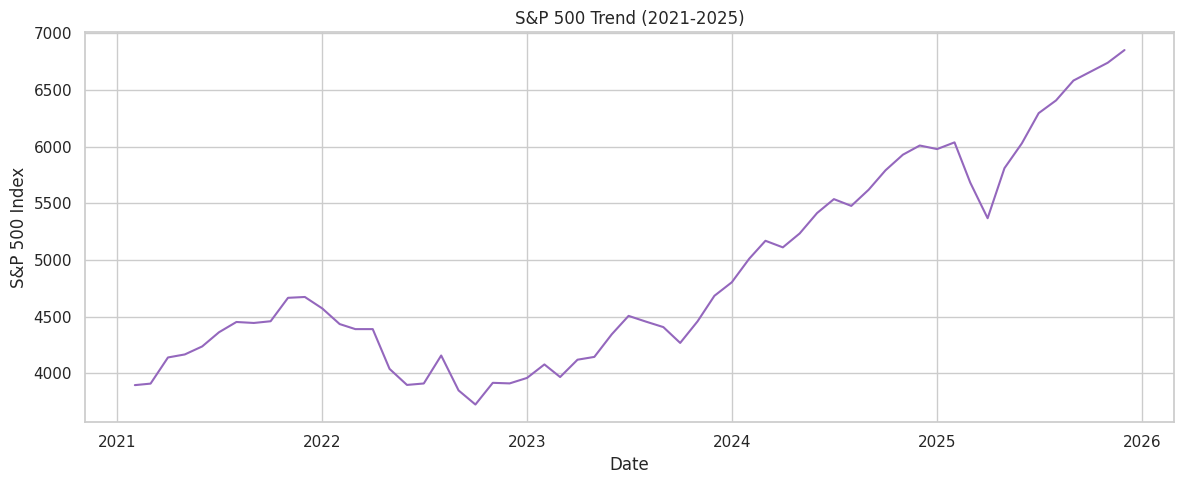

In [5]:
lineplot(full, "SP500", "S&P 500 Trend (2021-2025)", "S&P 500 Index", "tab:purple", "sp500_trend_recent.png")

## Correlations

Two separate correlation views, matching the two datasets:
- **Long history** (CPI, unemployment, Fed Funds) — 70 years, statistically much more reliable
- **Recent period incl. SP500** — only ~5 years, so treat these correlations as a
  snapshot of one particular economic cycle rather than a stable long-run relationship

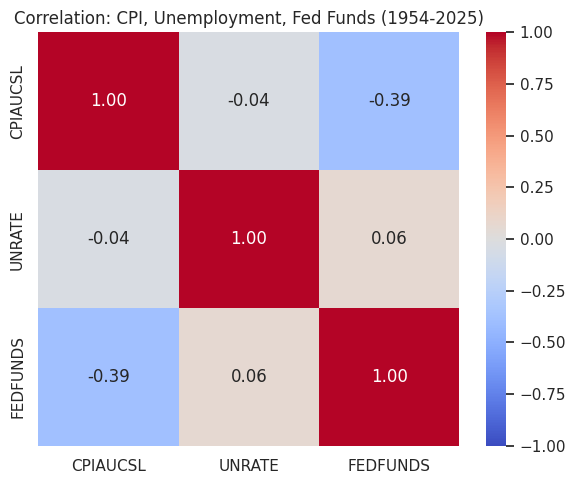

,CPIAUCSL,UNRATE,FEDFUNDS
CPIAUCSL,1.000000,-0.037766,-0.386859
UNRATE,-0.037766,1.000000,0.064047
FEDFUNDS,-0.386859,0.064047,1.000000


In [6]:
plt.figure(figsize=(6, 5))
corr_long = macro[["CPIAUCSL", "UNRATE", "FEDFUNDS"]].corr()
sns.heatmap(corr_long, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation: CPI, Unemployment, Fed Funds (1954-2025)")
plt.tight_layout()
plt.savefig(VIS + "correlation_heatmap_long_history.png", dpi=150)
plt.show()
corr_long

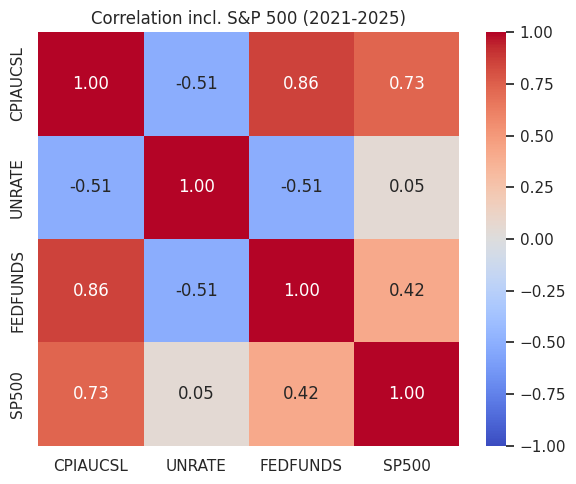

,CPIAUCSL,UNRATE,FEDFUNDS,SP500
CPIAUCSL,1.000000,-0.513855,0.858555,0.727542
UNRATE,-0.513855,1.000000,-0.513421,0.051661
FEDFUNDS,0.858555,-0.513421,1.000000,0.415126
SP500,0.727542,0.051661,0.415126,1.000000


In [7]:
plt.figure(figsize=(6, 5))
corr_recent = full[["CPIAUCSL", "UNRATE", "FEDFUNDS", "SP500"]].corr()
sns.heatmap(corr_recent, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation incl. S&P 500 (2021-2025)")
plt.tight_layout()
plt.savefig(VIS + "correlation_heatmap_recent_with_sp500.png", dpi=150)
plt.show()
corr_recent

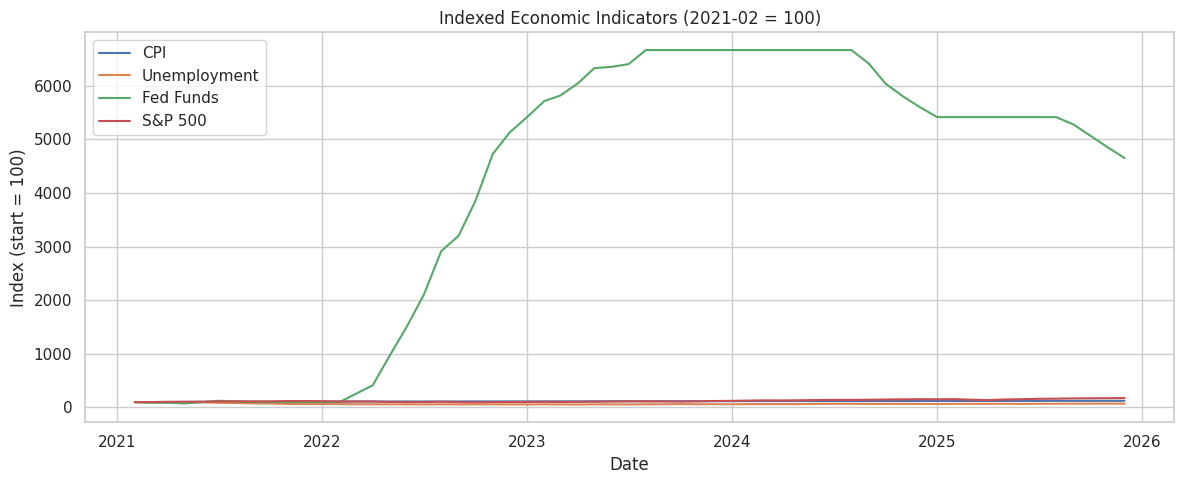

In [8]:
# Indexed comparison (2021-02 = 100) so all four series are visible on one chart
# despite very different scales (CPI ~300, FEDFUNDS ~4, SP500 ~6000)
plt.figure(figsize=(12, 5))
idx = full.set_index("observation_date")
for col, lbl in [("CPIAUCSL", "CPI"), ("UNRATE", "Unemployment"), ("FEDFUNDS", "Fed Funds"), ("SP500", "S&P 500")]:
    series = idx[col] / idx[col].iloc[0] * 100
    plt.plot(series.index, series.values, label=lbl)
plt.title("Indexed Economic Indicators (2021-02 = 100)")
plt.xlabel("Date"); plt.ylabel("Index (start = 100)"); plt.legend(); plt.grid(True)
plt.tight_layout()
plt.savefig(VIS + "indexed_indicators_2021_2025.png", dpi=150)
plt.show()

## Key findings

- **CPI and Fed Funds move together over the long run** (positive correlation across
  1954-2025) — consistent with the Fed raising rates to fight inflation, exactly what
  played out in 2022-2023.
- **Unemployment is negatively correlated with Fed Funds** over the long run, broadly
  consistent with the Phillips-curve idea that tighter monetary policy cools the labor
  market.
- In the 2021-2025 window, **SP500 shows a strong positive correlation with CPI and
  Fed Funds** — but this is a *short, single-cycle* correlation (post-COVID recovery +
  AI-driven rally happened to coincide with the hiking cycle), not necessarily a stable
  structural relationship. It shouldn't be read as "rate hikes push stocks up" — the
  history here is too short and too dominated by one episode to support that claim.
- The indexed chart makes the relative scale of moves clear: over 2021-2025, Fed Funds
  moved the most in *relative* terms (from near-zero), followed by S&P 500, with CPI the
  most stable in relative terms despite being the number most people were paying
  attention to.